# Representativeness evaluation — all numerical features

Three genre- and window-specific comparisons share the **original Top-1 genre as baseline** and use the **standard deviation of all eligible songs in that feature and five-year window** as the common scale:

1. **Selected vs Top-1:** all songs assigned to the genre by OR-Tools versus its original Top-1 songs.
2. **All songs vs Top-1:** the entire genre-independent song pool versus the original Top-1 genre.
3. **Assigned Top-2 vs Top-1:** only the songs OR-Tools assigned to a genre **different from their original Top-1 genre**, versus the original Top-1 genre. With a Top-2 candidate restriction, these are the reassigned second-choice songs.

Each feature difference is calculated first; the **median absolute standardized difference** is the primary heatmap statistic. The 90th percentile remains available for diagnosing atypical features. The assigned Top-2 comparison requires **at least 20 reassigned songs per genre-window-feature and at least 20 original Top-1 reference songs**. Missing comparisons are left blank rather than treated as zero. Each plotted group uses available valid feature-window comparisons; the number of available comparisons may differ among the three panels.

Original Top-1-standardized SMD columns are also retained as secondary diagnostics. Bootstrap confidence intervals **continue to evaluate selected assignments vs Top-1** for all eligible features in configured example genre-windows, not every genre-window and not the separate Top-2 subgroup. The global standard deviation is held fixed during bootstrap resampling.

All numerical columns are examined, including some technical and categorical numerical features. Consider the feature types when interpreting aggregate results, particularly sparse lyrics TF-IDF features.


In [2]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


In [3]:
ROOT = Path("../../..")
RAW_DIR = ROOT / "data" / "raw"
RUNS_DIR = ROOT / "data" / "processed" / "01_selected_genres_ortools" / "runs"
PATH_SELECTED_DATASET = RUNS_DIR / "ortools_top50_mintracks20_topcandidates2_genrepool1000_interpretable_time600"
OUTPUT_DIR = Path("plots")
PLOT_DIR = Path("plots")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
RUN_PREFIX = None
TOTAL_GENRES = 50
MIN_TRACKS = 20
TOP_CANDIDATES = 2
START_YEAR = 1955
END_YEAR = 2019
WINDOW_SIZE = 5

MIN_SAMPLE = 20
BOOTSTRAP_REPS = 500
BOOTSTRAP_YEARS = [1980, 2000, 2015]
BOOTSTRAP_EXAMPLES_PER_MODALITY_YEAR = 2
BOOTSTRAP_REP_BATCH = 50
BOOTSTRAP_FEATURE_BATCH = 64
BOOTSTRAP_PLOT_LIMIT = 30
SEED = 42

FILES = {
    "metadata": RAW_DIR / "id_metadata.csv",
    "essentia": RAW_DIR / "id_essentia.tsv",
    "lyrics_tf_idf": RAW_DIR / "id_lyrics_tf-idf.tsv",
}

MODALITIES = list(FILES)
WINDOW_STARTS = list(range(START_YEAR, END_YEAR - WINDOW_SIZE + 2))


In [5]:
with (PATH_SELECTED_DATASET / "run_metadata.json").open(encoding="utf-8") as f:
    run_info = json.load(f)

assignments = pd.read_parquet(PATH_SELECTED_DATASET / "assignments.parquet")[["id", "genre"]].drop_duplicates("id")
selected_genres = pd.read_csv(PATH_SELECTED_DATASET / "selected_genres.csv")["genre"].drop_duplicates().tolist()
assignments["id"] = assignments["id"].astype(str)
assignments["genre"] = assignments["genre"].astype(str)
print("Run:", PATH_SELECTED_DATASET.name)
print("Solver status:", run_info["solver"]["solver_status"])
print("Assigned songs:", len(assignments))
print("Selected genres:", len(selected_genres))

Run: ortools_top50_mintracks20_topcandidates2_genrepool1000_interpretable_time600
Solver status: OPTIMAL
Assigned songs: 87858
Selected genres: 50


In [6]:
def read_raw(path, columns=None, nrows=None, chunksize=None):
    return pd.read_csv(
        path,
        sep="\t",
        usecols=columns,
        nrows=nrows,
        chunksize=chunksize,
        dtype={"id": str},
    )


catalog = read_raw(FILES["metadata"], columns=["id", "release"])
catalog["release"] = pd.to_numeric(catalog["release"], errors="coerce")
catalog = catalog.dropna(subset=["release"]).drop_duplicates("id")
catalog = catalog[catalog["release"].between(START_YEAR, END_YEAR)].copy()
catalog["release"] = catalog["release"].astype(int)

for modality in ["essentia", "lyrics_tf_idf"]:
    available_ids = set(read_raw(FILES[modality], columns=["id"])["id"])
    catalog = catalog[catalog["id"].isin(available_ids)].copy()

score_file = RAW_DIR / "id_genres_tf-idf.tsv"
top1_parts = []
for chunk in read_raw(score_file, chunksize=2000):
    chunk = chunk[chunk["id"].isin(catalog["id"])].copy()
    if chunk.empty:
        continue
    scores = chunk.drop(columns=["id"]).apply(pd.to_numeric, errors="coerce")
    top1_parts.append(pd.DataFrame({
        "id": chunk["id"].to_numpy(),
        "top1_genre": scores.idxmax(axis=1).to_numpy(),
        "top1_score": scores.max(axis=1).to_numpy(),
    }))

top1 = pd.concat(top1_parts, ignore_index=True)
top1 = top1[top1["top1_score"] > 0].drop(columns="top1_score")
catalog = catalog.merge(top1, on="id", how="inner", validate="one_to_one")
assignments = assignments[assignments["id"].isin(catalog["id"])].copy()
print("Eligible songs in all modalities:", len(catalog))
print("Selected assignments in eligible pool:", len(assignments))
print("Top-1 genres in eligible pool:", catalog["top1_genre"].nunique())

Eligible songs in all modalities: 109075
Selected assignments in eligible pool: 87858
Top-1 genres in eligible pool: 684


In [7]:
song_tables = {}
feature_sets = {}

for modality in MODALITIES:
    columns = read_raw(FILES[modality], nrows=0).columns.tolist()
    features = [col for col in columns if col not in ["id", "release"]]

    frame = read_raw(FILES[modality], columns=["id", *features]).drop_duplicates("id")
    numeric = frame[features].apply(pd.to_numeric, errors="coerce", downcast="float")
    features = numeric.columns[numeric.notna().any(axis=0)].tolist()

    frame = pd.concat([frame[["id"]].reset_index(drop=True), numeric[features].reset_index(drop=True)], axis=1)
    frame = catalog.merge(frame, on="id", how="inner", validate="one_to_one")

    song_tables[modality] = frame
    feature_sets[modality] = features
    print(modality, len(frame), "songs,", len(features), "numerical features")


metadata 109075 songs, 8 numerical features
essentia 109075 songs, 1034 numerical features
lyrics_tf_idf 109075 songs, 1000 numerical features


In [8]:
def grouped_stats(frame, group_col, features, prefix):
    stats = frame.groupby(group_col)[features].agg(["mean", "std", "count"])
    stats = stats.stack(level=0, future_stack=True).rename_axis(["genre", "feature"]).reset_index()
    return stats.rename(columns={"mean": prefix + "_mean", "std": prefix + "_std", "count": prefix + "_n"})


comparison_parts = []

for modality, songs in song_tables.items():
    features = feature_sets[modality]
    selected_songs = assignments.merge(songs, on="id", how="inner")
    selected_top2_songs = selected_songs[selected_songs["genre"] != selected_songs["top1_genre"]]
    print("Calculating:", modality, len(features), "features")

    for start in WINDOW_STARTS:
        stop = start + WINDOW_SIZE - 1
        global_window = songs[songs["release"].between(start, stop)]
        selected_window = selected_songs[selected_songs["release"].between(start, stop)]
        top2_window = selected_top2_songs[selected_top2_songs["release"].between(start, stop)]
        if global_window.empty or selected_window.empty:
            continue

        top1_window = global_window[global_window["top1_genre"].isin(selected_genres)]
        a = grouped_stats(selected_window, "genre", features, "selected")
        b = grouped_stats(top1_window, "top1_genre", features, "baseline")
        c = global_window[features].agg(["mean", "std", "count"]).T.reset_index()
        c.columns = ["feature", "global_mean", "global_std", "global_n"]

        comp = a.merge(b, on=["genre", "feature"], how="left").merge(c, on="feature", how="left")
        if not top2_window.empty:
            top2_stats = grouped_stats(top2_window, "genre", features, "assigned_top2")
            comp = comp.merge(top2_stats, on=["genre", "feature"], how="left")
        else:
            for name in ["assigned_top2_mean", "assigned_top2_std", "assigned_top2_n"]:
                comp[name] = np.nan

        enough = (comp["selected_n"] >= MIN_SAMPLE) & (comp["baseline_n"] >= MIN_SAMPLE)
        enough_top2 = enough & (comp["assigned_top2_n"] >= MIN_SAMPLE)
        valid_top1 = enough & np.isfinite(comp["baseline_std"]) & (comp["baseline_std"] > 0)
        valid_common = enough & (comp["global_n"] >= MIN_SAMPLE) & np.isfinite(comp["global_std"]) & (comp["global_std"] > 0)
        valid_top2 = valid_common & enough_top2

        comp["smd_top1"] = ((comp["selected_mean"] - comp["baseline_mean"]) / comp["baseline_std"]).where(valid_top1)
        comp["smd_global"] = ((comp["selected_mean"] - comp["global_mean"]) / comp["global_std"]).where((comp["selected_n"] >= MIN_SAMPLE) & (comp["global_std"] > 0))
        comp["smd_all_songs_to_top1"] = ((comp["global_mean"] - comp["baseline_mean"]) / comp["baseline_std"]).where(valid_top1 & (comp["global_n"] >= MIN_SAMPLE))
        comp["smd_assigned_top2_top1"] = ((comp["assigned_top2_mean"] - comp["baseline_mean"]) / comp["baseline_std"]).where(valid_top1 & enough_top2)
        comp["std_ratio"] = (comp["selected_std"] / comp["baseline_std"]).where(valid_top1)

        comp["smd_selected_common"] = ((comp["selected_mean"] - comp["baseline_mean"]) / comp["global_std"]).where(valid_common)
        comp["smd_all_common"] = ((comp["global_mean"] - comp["baseline_mean"]) / comp["global_std"]).where(valid_common)
        comp["smd_assigned_top2_common"] = ((comp["assigned_top2_mean"] - comp["baseline_mean"]) / comp["global_std"]).where(valid_top2)
        comp["modality"] = modality
        comp["window_start"] = start
        comp["window_end"] = stop
        comparison_parts.append(comp)

comparisons = pd.concat(comparison_parts, ignore_index=True)
for col in ["smd_top1", "smd_selected_common", "smd_all_common", "smd_assigned_top2_common", "smd_assigned_top2_top1"]:
    comparisons[col] = comparisons[col].replace([np.inf, -np.inf], np.nan)

print("Compared feature/genre/window rows:", len(comparisons))
print("Valid original Top-1 SMD:", comparisons["smd_top1"].notna().sum())
print("Valid common-SD selected comparisons:", comparisons["smd_selected_common"].notna().sum())
print("Valid common-SD assigned Top-2 comparisons:", comparisons["smd_assigned_top2_common"].notna().sum())
display(comparisons.head())


Calculating: metadata 8 features
Calculating: essentia 1034 features
Calculating: lyrics_tf_idf 1000 features
Compared feature/genre/window rows: 5094790
Valid original Top-1 SMD: 2858718
Valid common-SD selected comparisons: 3525586
Valid common-SD assigned Top-2 comparisons: 1849079


,genre,feature,selected_mean,selected_std,selected_n,baseline_mean,baseline_std,baseline_n,global_mean,global_std,...,smd_global,smd_all_songs_to_top1,smd_assigned_top2_top1,std_ratio,smd_selected_common,smd_all_common,smd_assigned_top2_common,modality,window_start,window_end
0,blues,popularity,39.812500,13.175826,48,34.680000,12.522380,25.0,38.838234,12.608714,...,0.077269,0.332064,0.701268,1.052182,0.407060,0.329790,0.696466,metadata,1955,1959
1,blues,danceability,0.533542,0.144964,48,0.471120,0.118842,25.0,0.508447,0.152982,...,0.164036,0.314089,1.012291,1.219796,0.408032,0.243996,0.786386,metadata,1955,1959
2,blues,energy,0.342367,0.234532,48,0.241132,0.173189,25.0,0.319657,0.233543,...,0.097240,0.453405,1.028859,1.354198,0.433474,0.336233,0.762974,metadata,1955,1959
3,blues,key,4.687500,3.603522,48,4.880000,3.655133,25.0,5.082353,3.477570,...,-0.113543,0.055361,-0.188144,0.985880,-0.055355,0.058188,-0.197751,metadata,1955,1959
4,blues,mode,0.833333,0.376622,48,0.720000,0.458258,25.0,0.708824,0.454974,...,0.273663,-0.024389,0.443150,0.821856,0.249098,-0.024565,0.446348,metadata,1955,1959


In [9]:
coverage_path = PATH_SELECTED_DATASET / "coverage.parquet"
coverage = pd.read_parquet(coverage_path)
coverage = coverage[coverage["window_start"].isin(WINDOW_STARTS) & coverage["modality"].isin(MODALITIES)]
valid_cells = int(coverage["eligible_window"].fillna(False).sum())
total_cells = len(selected_genres) * len(WINDOW_STARTS) * len(MODALITIES)

summary = pd.DataFrame({
    "measure": ["Selected genres", "Assigned songs", "Eligible multimodal songs", "Original Top-1 songs in selected genres", "Time windows", "Modalities", "Valid coverage cells", "Possible coverage cells", "Coverage (%)"],
    "value": [len(selected_genres), len(assignments), len(catalog), int(catalog["top1_genre"].isin(selected_genres).sum()), len(WINDOW_STARTS), len(MODALITIES), valid_cells, total_cells, round(100 * valid_cells / total_cells, 2)],
})
display(summary)

matched = comparisons.dropna(subset=["smd_selected_common", "smd_all_common"]).copy()
matched["abs_selected_common"] = matched["smd_selected_common"].abs()
matched["abs_all_common"] = matched["smd_all_common"].abs()
matched["abs_assigned_top2_common"] = matched["smd_assigned_top2_common"].abs()

feature_scores = matched.groupby(["modality", "feature"], as_index=False).agg(
    median_abs_selected_common=("abs_selected_common", "median"),
    median_abs_all_common=("abs_all_common", "median"),
    median_abs_assigned_top2_common=("abs_assigned_top2_common", "median"),
    p90_abs_selected_common=("abs_selected_common", lambda x: x.quantile(0.9)),
    p90_abs_assigned_top2_common=("abs_assigned_top2_common", lambda x: x.quantile(0.9)),
    compared_cells=("abs_selected_common", "count"),
    top2_compared_cells=("abs_assigned_top2_common", "count"),
)

original_scores = comparisons.groupby(["modality", "feature"], as_index=False).agg(
    mean_abs_smd_top1=("smd_top1", lambda x: x.abs().mean()),
    mean_abs_smd_global=("smd_global", lambda x: x.abs().mean()),
    mean_abs_smd_assigned_top2=("smd_assigned_top2_top1", lambda x: x.abs().mean()),
    median_std_ratio=("std_ratio", "median"),
)
feature_scores = feature_scores.merge(original_scores, on=["modality", "feature"], how="left")

modality_scores = feature_scores.groupby("modality", as_index=False).agg(
    median_abs_selected_common=("median_abs_selected_common", "median"),
    median_abs_all_common=("median_abs_all_common", "median"),
    median_abs_assigned_top2_common=("median_abs_assigned_top2_common", "median"),
    median_feature_p90_common=("p90_abs_selected_common", "median"),
    median_feature_p90_top2_common=("p90_abs_assigned_top2_common", "median"),
    mean_abs_smd_top1=("mean_abs_smd_top1", "mean"),
    median_std_ratio=("median_std_ratio", "median"),
    features=("feature", "nunique"),
    assigned_top2_compared_cells=("top2_compared_cells", "sum"),
)
display(modality_scores.round(3))
print("Original Top-1-based SMD (mean of feature and modality averages):", round(modality_scores["mean_abs_smd_top1"].mean(), 3))
print("Common-SD median absolute standardized difference (equal-weight modality medians):", round(modality_scores["median_abs_selected_common"].median(), 3))
display(feature_scores.sort_values("p90_abs_selected_common", ascending=False).head(15))


,measure,value
0,Selected genres,50.00
1,Assigned songs,87858.00
2,Eligible multimodal songs,109075.00
3,Original Top-1 songs in selected genres,61175.00
4,Time windows,61.00
5,Modalities,3.00
6,Valid coverage cells,6495.00
7,Possible coverage cells,9150.00
8,Coverage (%),70.98


,modality,median_abs_selected_common,median_abs_all_common,median_abs_assigned_top2_common,median_feature_p90_common,median_feature_p90_top2_common,mean_abs_smd_top1,median_std_ratio,features,assigned_top2_compared_cells
0,essentia,0.030,0.164,0.116,0.118,0.331,3.554,0.992,845,842272
1,lyrics_tf_idf,0.010,0.084,0.070,0.089,0.272,0.046,0.952,1000,998799
2,metadata,0.032,0.262,0.135,0.127,0.377,0.067,0.999,8,8008


Original Top-1-based SMD (mean of feature and modality averages): 1.222
Common-SD median absolute standardized difference (equal-weight modality medians): 0.03


,modality,feature,median_abs_selected_common,median_abs_all_common,median_abs_assigned_top2_common,p90_abs_selected_common,p90_abs_assigned_top2_common,compared_cells,top2_compared_cells,mean_abs_smd_top1,mean_abs_smd_global,mean_abs_smd_assigned_top2,median_std_ratio
1846,metadata,duration_ms,0.032346,0.192470,0.138523,0.167666,0.572351,1911,1001,0.082340,0.288059,0.261039,1.002175
1850,metadata,popularity,0.041407,0.334042,0.186668,0.162044,0.506104,1911,1001,0.086121,0.400193,0.287600,0.999815
191,essentia,lowlevel.melbands.mean_2,0.034074,0.223913,0.146766,0.160242,0.447713,1911,1001,0.073148,0.252644,0.224677,0.994021
354,essentia,lowlevel.melbands128.mean_7,0.033496,0.207015,0.137645,0.157753,0.437284,1911,1001,0.072225,0.236347,0.222531,0.993726
21,essentia,lowlevel.barkbands.mean_3,0.034363,0.213270,0.137789,0.156882,0.438373,1911,1001,0.072097,0.240116,0.220861,0.993507
91,essentia,lowlevel.erbbands.mean_3,0.032911,0.215480,0.136564,0.155732,0.450881,1911,1001,0.071547,0.247869,0.218821,0.993558
102,essentia,lowlevel.erbbands.mean_4,0.038223,0.209909,0.144132,0.150965,0.408748,1911,1001,0.072891,0.238514,0.221539,0.997639
156,essentia,lowlevel.erbbands_spread.mean,0.036690,0.226266,0.152264,0.149828,0.387244,1911,1001,0.065769,0.284915,0.208219,1.000000
332,essentia,lowlevel.melbands128.mean_5,0.030748,0.198156,0.135000,0.149263,0.429086,1911,1001,0.068669,0.229783,0.209157,0.995427
532,essentia,lowlevel.mfcc.mean_4,0.035154,0.152365,0.136672,0.148569,0.398435,1911,1001,0.062314,0.202832,0.187729,0.996714


Share of selected assignments matching the original Top-1: 69.3 %


,genre,assigned_songs,first_release,last_release,share_top1
30,pop,10578,1955,2019,0.727548
23,indie rock,4884,1975,2019,0.716626
14,electronic,4577,1970,2019,0.526983
43,singer-songwriter,3742,1962,2019,0.843132
38,rap,3529,1981,2019,0.541797
40,rock,3387,1956,2019,0.626513
46,soul,3295,1956,2019,0.835508
0,alternative rock,3153,1980,2019,0.692039
21,hard rock,2499,1964,2019,0.752701
16,folk,2376,1958,2019,0.680135


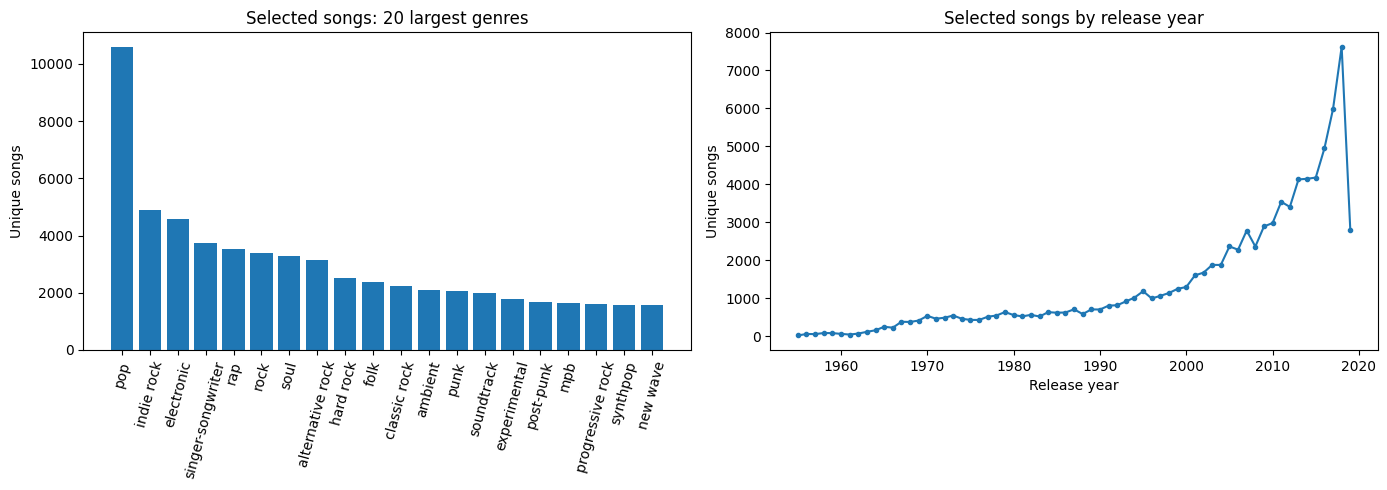

In [10]:
assigned_with_info = assignments.merge(catalog, on="id", how="inner")
assigned_with_info["is_original_top1"] = assigned_with_info["genre"].eq(assigned_with_info["top1_genre"])

per_genre = assigned_with_info.groupby("genre", as_index=False).agg(
    assigned_songs=("id", "nunique"),
    first_release=("release", "min"),
    last_release=("release", "max"),
    share_top1=("is_original_top1", "mean"),
).sort_values("assigned_songs", ascending=False)

per_year = assigned_with_info.groupby("release", as_index=False)["id"].nunique().rename(columns={"release": "year", "id": "selected_songs"})
print("Share of selected assignments matching the original Top-1:", round(100 * assigned_with_info["is_original_top1"].mean(), 1), "%")
display(per_genre.head(15))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(per_genre.head(20)["genre"], per_genre.head(20)["assigned_songs"])
axes[0].tick_params(axis="x", rotation=75)
axes[0].set_title("Selected songs: 20 largest genres")
axes[0].set_ylabel("Unique songs")
axes[1].plot(per_year["year"], per_year["selected_songs"], marker=".")
axes[1].set_title("Selected songs by release year")
axes[1].set_xlabel("Release year")
axes[1].set_ylabel("Unique songs")
plt.tight_layout()
fig.savefig(PLOT_DIR / "selected_dataset_composition.png", dpi=250, bbox_inches="tight")
plt.show()
per_genre.to_csv(OUTPUT_DIR / "selected_songs_by_genre.csv", index=False)
per_year.to_csv(OUTPUT_DIR / "selected_songs_by_year.csv", index=False)

Overall genre-window coverage: 70.98 %
Valid genre-window combinations: 2165
Equivalent cells across 3 modalities: 6495
Original valid cells: 6495


,window_start,window_end,valid_genres,coverage_percent,genres_without_songs,genres_below_threshold
0,1955,1959,5,10.0,39,6
1,1956,1960,6,12.0,39,5
2,1957,1961,6,12.0,38,6
3,1958,1962,6,12.0,36,8
4,1959,1963,9,18.0,36,5
5,1960,1964,9,18.0,34,7
6,1961,1965,11,22.0,32,7
7,1962,1966,10,20.0,30,10
8,1963,1967,14,28.0,25,11
9,1964,1968,15,30.0,25,10


,window_start,window_end,valid_genres,coverage_percent,genres_without_songs,genres_below_threshold
51,2006,2010,50,100.0,0,0
52,2007,2011,49,98.0,0,1
53,2008,2012,49,98.0,0,1
54,2009,2013,50,100.0,0,0
55,2010,2014,50,100.0,0,0
56,2011,2015,49,98.0,0,1
57,2012,2016,50,100.0,0,0
58,2013,2017,50,100.0,0,0
59,2014,2018,50,100.0,0,0
60,2015,2019,50,100.0,0,0


,genre,valid_windows,coverage_percent,first_valid_window
6,britpop,31,50.82,1985
31,post-hardcore,31,50.82,1985
44,ska,31,50.82,1977
23,indie rock,32,52.46,1984
34,progressive metal,32,52.46,1984
38,rap,32,52.46,1984
20,grunge,32,52.46,1984
11,doom metal,33,54.10,1983
9,death metal,33,54.10,1983
19,gothic rock,34,55.74,1977


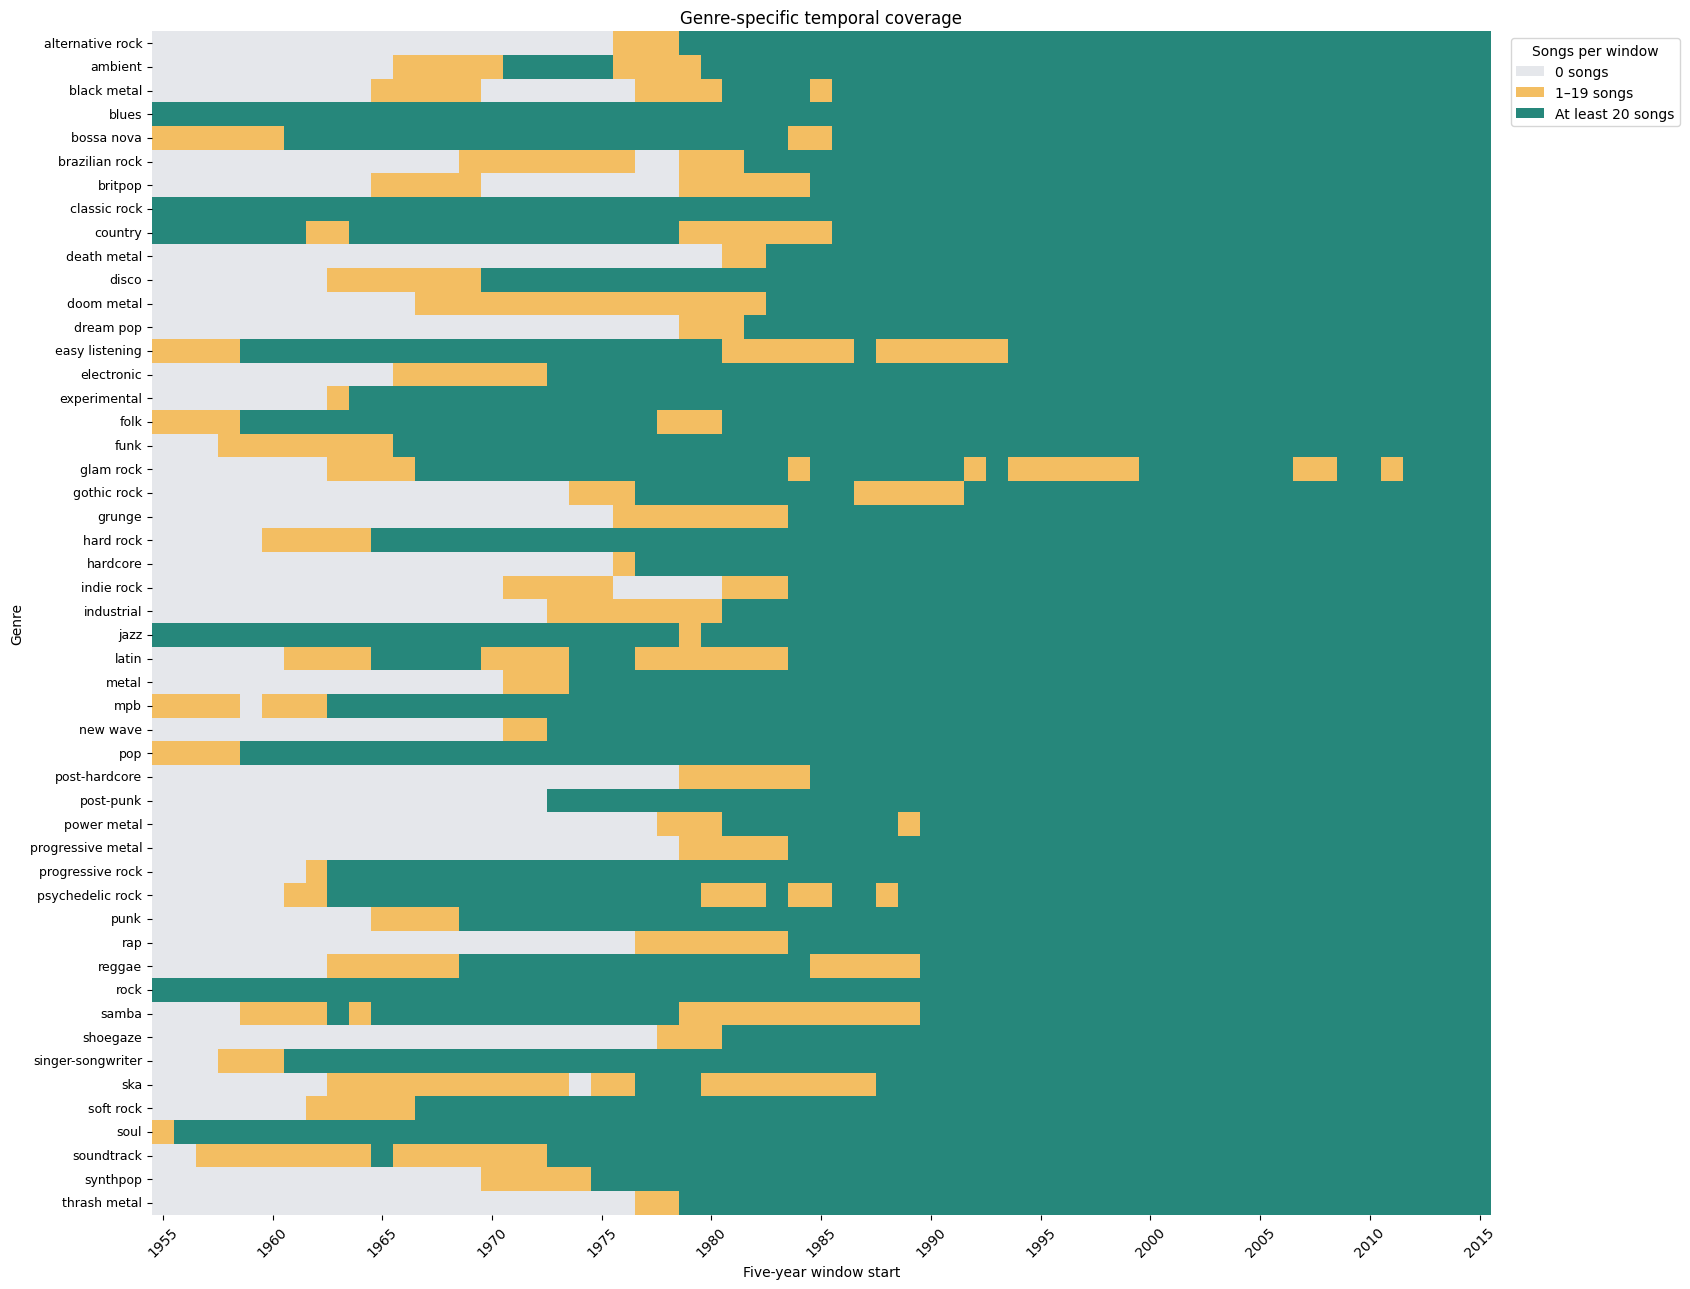

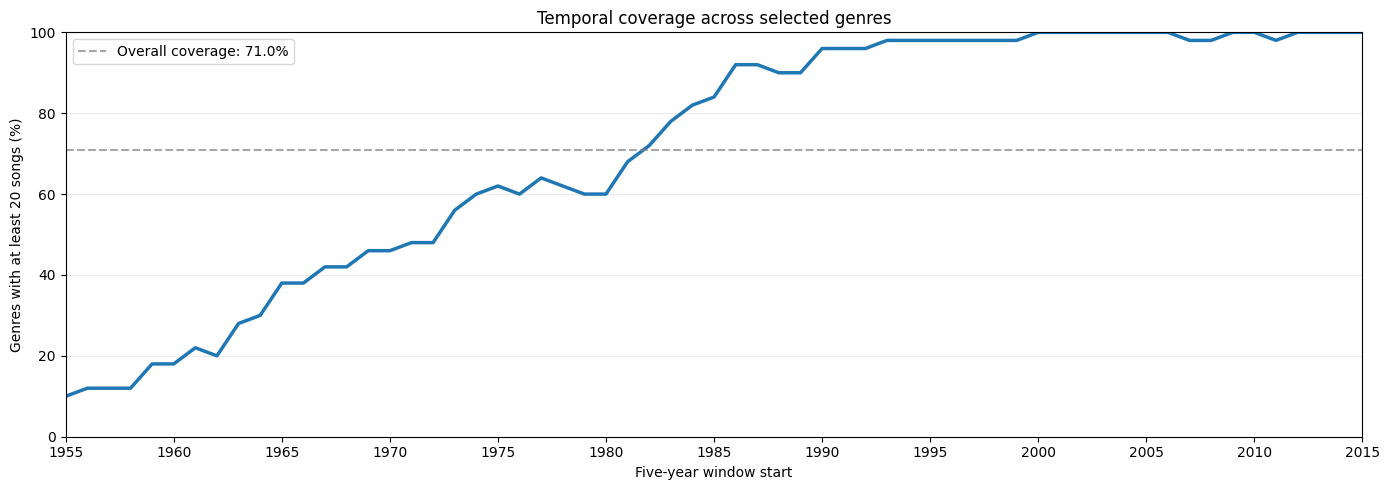

In [11]:
from matplotlib.colors import PowerNorm

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

genres = sorted(selected_genres)

yearly_counts = (
    assigned_with_info
    .groupby(["genre", "release"])["id"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(
        index=genres,
        columns=range(START_YEAR, END_YEAR + 1),
        fill_value=0
    )
)

track_counts = pd.DataFrame({
    start: yearly_counts.loc[
        :, start:start + WINDOW_SIZE - 1
    ].sum(axis=1)
    for start in WINDOW_STARTS
})

coverage_valid = track_counts >= MIN_TRACKS

coverage_state = (
    (track_counts > 0).astype(int)
    + coverage_valid.astype(int)
)

window_summary = pd.DataFrame({
    "window_start": WINDOW_STARTS,
    "window_end": [
        start + WINDOW_SIZE - 1
        for start in WINDOW_STARTS
    ],
    "valid_genres": coverage_valid.sum(axis=0).to_numpy(),
    "coverage_percent": (
        100 * coverage_valid.mean(axis=0)
    ).round(2).to_numpy(),
    "genres_without_songs": (
        coverage_state == 0
    ).sum(axis=0).to_numpy(),
    "genres_below_threshold": (
        coverage_state == 1
    ).sum(axis=0).to_numpy()
})

genre_summary = pd.DataFrame({
    "genre": genres,
    "valid_windows": coverage_valid.sum(axis=1).to_numpy(),
    "coverage_percent": (
        100 * coverage_valid.mean(axis=1)
    ).round(2).to_numpy(),
    "first_valid_window": coverage_valid.apply(
        lambda row: row.index[row].min() if row.any() else np.nan,
        axis=1
    ).to_numpy()
})

overall_coverage = 100 * coverage_valid.to_numpy().mean()

print("Overall genre-window coverage:", round(overall_coverage, 2), "%")
print("Valid genre-window combinations:", int(coverage_valid.to_numpy().sum()))
print("Equivalent cells across 3 modalities:", int(coverage_valid.to_numpy().sum() * len(MODALITIES)))
print("Original valid cells:", valid_cells)

display(window_summary.head(10))
display(window_summary.tail(10))
display(genre_summary.sort_values("coverage_percent").head(15))

colors = ["#E5E7EB", "#F3BE62", "#26877B"]

fig, ax = plt.subplots(
    figsize=(17, max(10, 0.26 * len(genres)))
)

sns.heatmap(
    coverage_state,
    ax=ax,
    cmap=ListedColormap(colors),
    norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3),
    cbar=False,
    linewidths=0
)

ax.set_xticks(np.arange(0.5, len(WINDOW_STARTS), 5))
ax.set_xticklabels(WINDOW_STARTS[::5], rotation=45)
ax.set_title("Genre-specific temporal coverage")
ax.set_xlabel("Five-year window start")
ax.set_ylabel("Genre")
ax.tick_params(axis="y", labelsize=9)

ax.legend(
    handles=[
        Patch(facecolor=colors[0], label="0 songs"),
        Patch(facecolor=colors[1], label=f"1–{MIN_TRACKS - 1} songs"),
        Patch(facecolor=colors[2], label=f"At least {MIN_TRACKS} songs")
    ],
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    title="Songs per window"
)

plt.tight_layout()
fig.savefig(
    PLOT_DIR / "genre_specific_temporal_coverage.png",
    dpi=250,
    bbox_inches="tight"
)
plt.show()

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    window_summary["window_start"],
    window_summary["coverage_percent"],
    linewidth=2.5
)

ax.axhline(
    overall_coverage,
    linestyle="--",
    color="gray",
    alpha=0.7,
    label=f"Overall coverage: {overall_coverage:.1f}%"
)

ax.set_title("Temporal coverage across selected genres")
ax.set_xlabel("Five-year window start")
ax.set_ylabel(f"Genres with at least {MIN_TRACKS} songs (%)")
ax.set_xticks(WINDOW_STARTS[::5])
ax.set_ylim(0, 100)
ax.set_xlim(WINDOW_STARTS[0], WINDOW_STARTS[-1])
ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.tight_layout()
fig.savefig(
    PLOT_DIR / "genre_coverage_share_by_window.png",
    dpi=250,
    bbox_inches="tight"
)
plt.show()

window_summary.to_csv(
    OUTPUT_DIR / "temporal_coverage_by_window.csv",
    index=False
)

genre_summary.to_csv(
    OUTPUT_DIR / "temporal_coverage_by_genre.csv",
    index=False
)



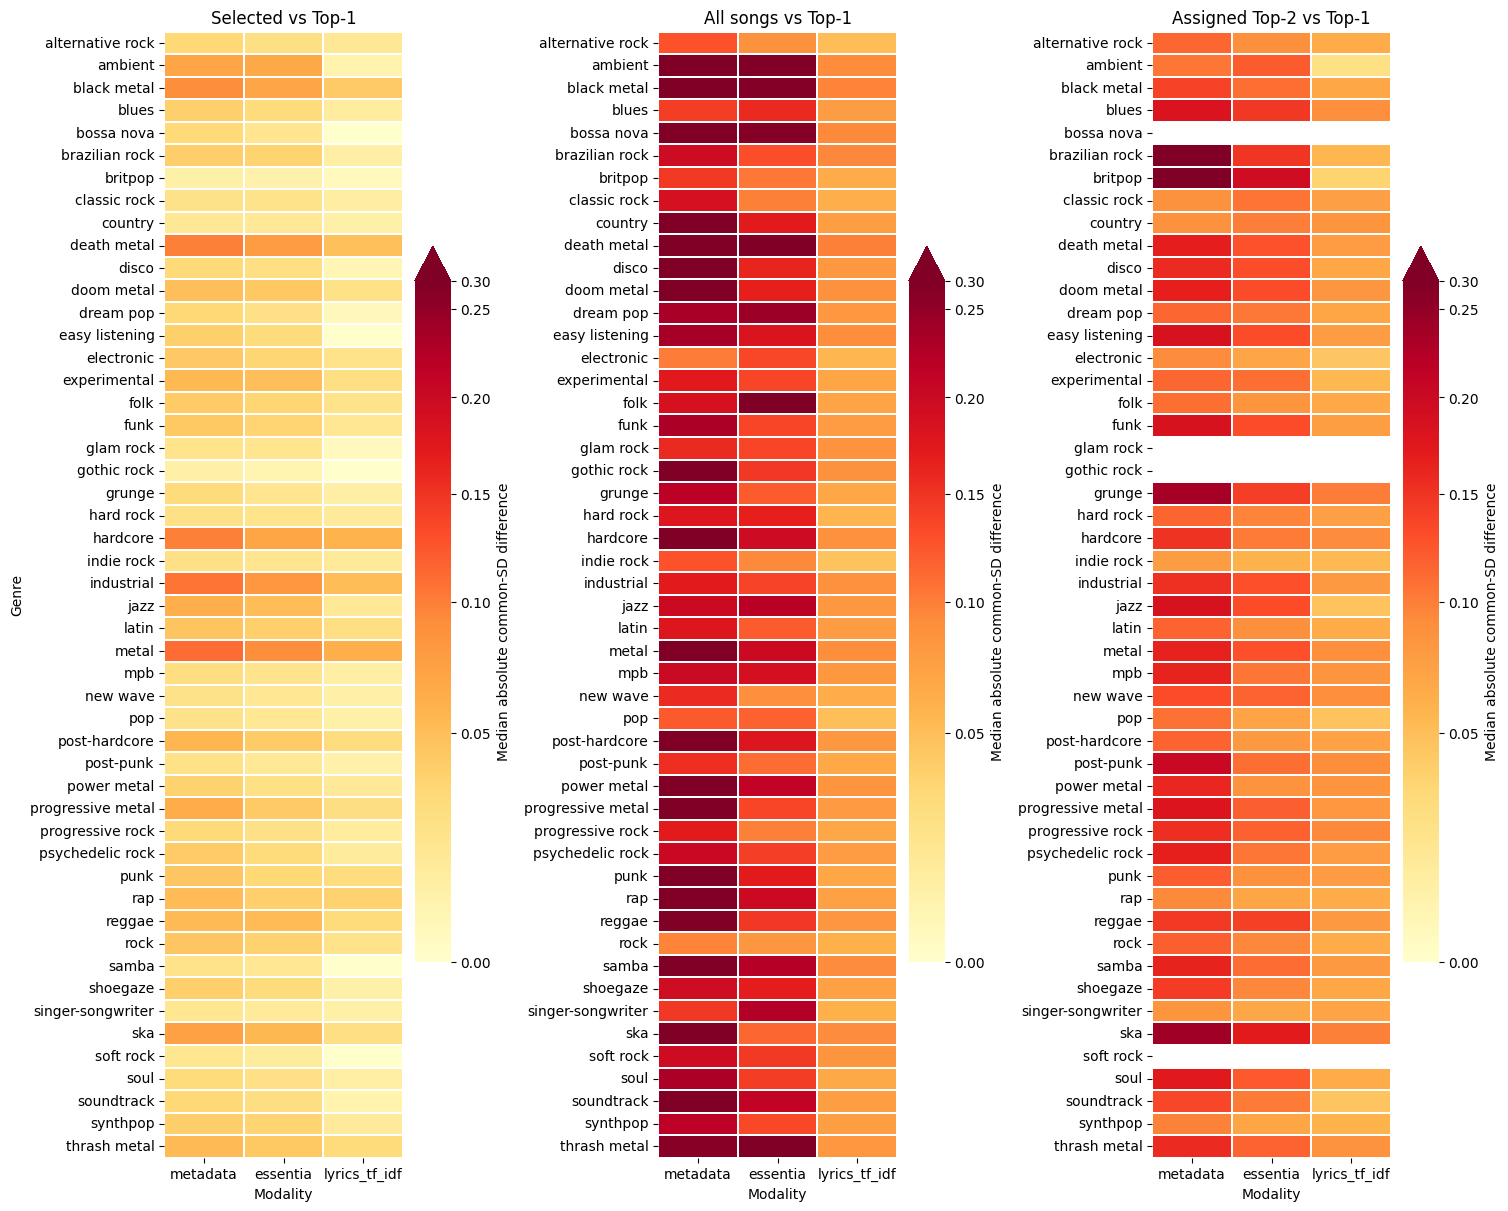

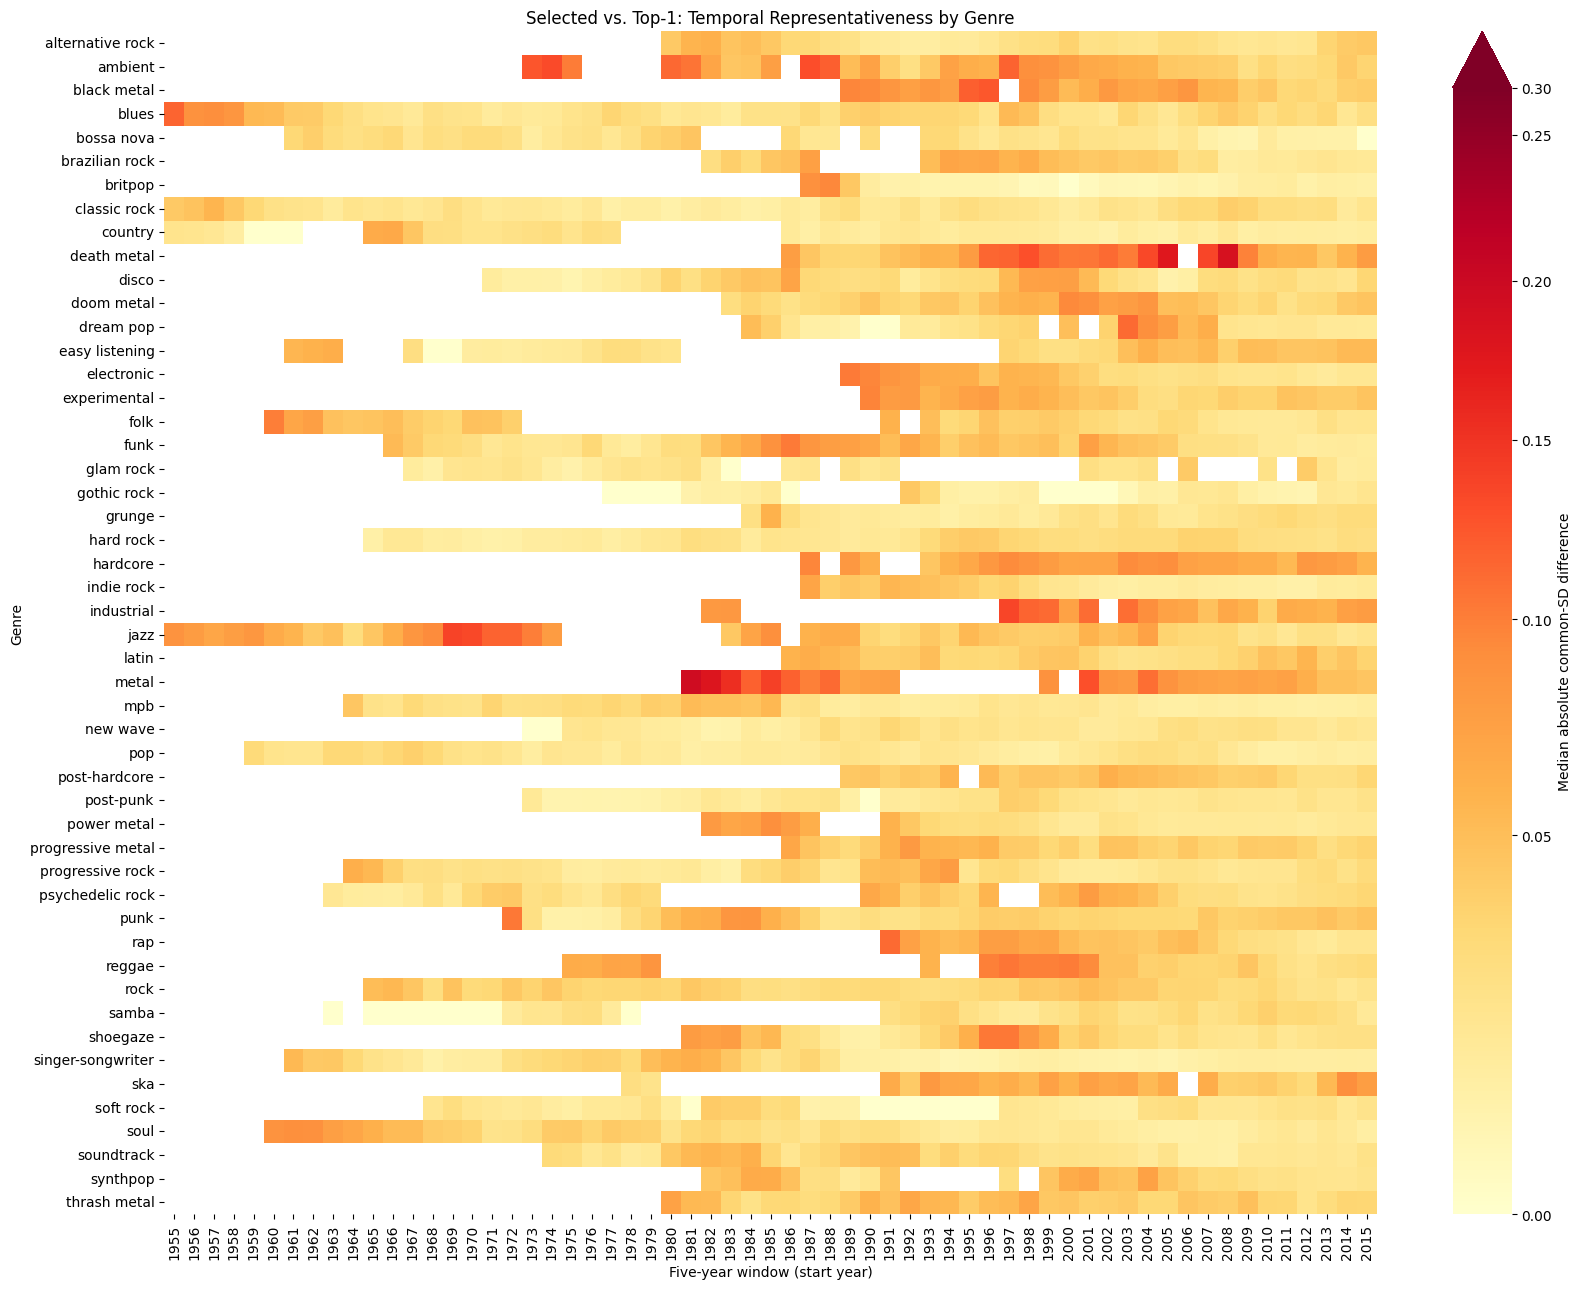

In [13]:
from matplotlib.colors import PowerNorm

heat = matched.groupby(["genre", "modality"], as_index=False).agg(
    top1=("abs_selected_common", "median"),
    global_all=("abs_all_common", "median"),
    assigned_top2=("abs_assigned_top2_common", "median"),
)

scales = heat[["top1", "global_all", "assigned_top2"]].to_numpy(dtype=float)
vmax = np.nanpercentile(scales, 95)
if not np.isfinite(vmax) or vmax <= 0:
    vmax = 1.0

fig, axes = plt.subplots(1, 3, figsize=(15, max(8, 0.24 * len(selected_genres))), constrained_layout=True)
for ax, key, title in zip(
    axes,
    ["top1", "global_all", "assigned_top2"],
    ["Selected vs Top-1", "All songs vs Top-1", "Assigned Top-2 vs Top-1"],
):
    matrix = heat.pivot(index="genre", columns="modality", values=key).reindex(index=sorted(selected_genres), columns=MODALITIES)
    sns.heatmap(
        matrix,
        ax=ax,
        cmap="YlOrRd",
        norm=PowerNorm(gamma=0.65, vmin=0, vmax=vmax, clip=True),
        mask=matrix.isna(),
        linewidths=0.15,
        cbar_kws={"label": "Median absolute common-SD difference", "extend": "max"},
    )
    ax.set_title(title)
    ax.set_xlabel("Modality")
    ax.set_ylabel("Genre" if ax is axes[0] else "")

fig.savefig(PLOT_DIR / "selected_vs_baselines_smd_by_genre_modality.png", dpi=250, bbox_inches="tight")
plt.show()

window_scores = matched.groupby(["genre", "window_start", "modality"], as_index=False).agg(
    median_abs_smd=("abs_selected_common", "median")
)

window_scores = matched.groupby(
    ["genre", "window_start", "modality"], as_index=False
).agg(
    median_abs_smd=("abs_selected_common", "median")
)

window_scores = window_scores.groupby(
    ["genre", "window_start"], as_index=False
)["median_abs_smd"].median()

window_matrix = window_scores.pivot(
    index="genre",
    columns="window_start",
    values="median_abs_smd"
)

window_matrix = window_matrix.reindex(
    index=sorted(selected_genres),
    columns=WINDOW_STARTS
)

fig, ax = plt.subplots(
    figsize=(17, max(8, 0.26 * len(selected_genres)))
)

sns.heatmap(
    window_matrix,
    ax=ax,
    cmap="YlOrRd",
    norm=PowerNorm(gamma=0.65, vmin=0, vmax=vmax, clip=True),
    mask=window_matrix.isna(),
    linewidths=0,
    cbar_kws={
        "label": "Median absolute common-SD difference",
        "extend": "max"
    }
)

ax.set_title("Selected vs. Top-1: Temporal Representativeness by Genre")
ax.set_xlabel("Five-year window (start year)")
ax.set_ylabel("Genre")

plt.tight_layout()

fig.savefig(
    PLOT_DIR / "selected_vs_top1_smd_genre_window_heatmap.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()


## Same-reference overview: selected assignments, global song pool, and assigned Top-2 songs

For each genre, numerical feature, and five-year window, all three comparisons use the **same Top-1 genre mean** as their baseline and the **standard deviation of all eligible songs** in that window as the denominator.

- **Selected vs Top-1:** `(selected_mean - baseline_mean) / global_std`
- **All songs vs Top-1:** `(global_mean - baseline_mean) / global_std`
- **Assigned Top-2 vs Top-1:** `(assigned_top2_mean - baseline_mean) / global_std`

The assigned Top-2 group consists **only of songs reassigned by OR-Tools to their non-Top-1 candidate genre**. This directly assesses the potential distributional effect of using Top-2 flexibility. A Top-2 estimate is shown only when **both the Top-2 subgroup and original Top-1 baseline contain at least `MIN_SAMPLE` non-missing feature values** and the global standard deviation is positive. Blank entries do not mean zero difference.

The heatmaps show **median absolute common-SD differences**, and the same color scale is applied to all three panels. There are fewer valid Assigned Top-2 comparisons than Selected comparisons; medians should therefore be interpreted together with their coverage counts. A larger Top-2 difference can coexist with a small Selected difference because selected songs include both original Top-1 and reassigned Top-2 songs.

The original Top-1-SD standardized scores are retained as secondary diagnostics. These statistics measure feature-mean similarity rather than proving that temporal trends or full distributions are preserved.


,modality,selected_vs_top1,all_songs_vs_top1,assigned_top2_vs_top1,compared_cells,top2_compared_cells
0,essentia,0.026,0.152,0.104,1605987,842272
1,lyrics_tf_idf,0.011,0.076,0.068,1904311,998799
2,metadata,0.034,0.213,0.135,15288,8008


,comparison,median_absolute_common_sd_difference,compared_cells
0,Selected vs Top-1,0.018,3525586
1,All songs vs Top-1,0.093,3525586
2,Assigned Top-2 vs Top-1,0.083,1849079


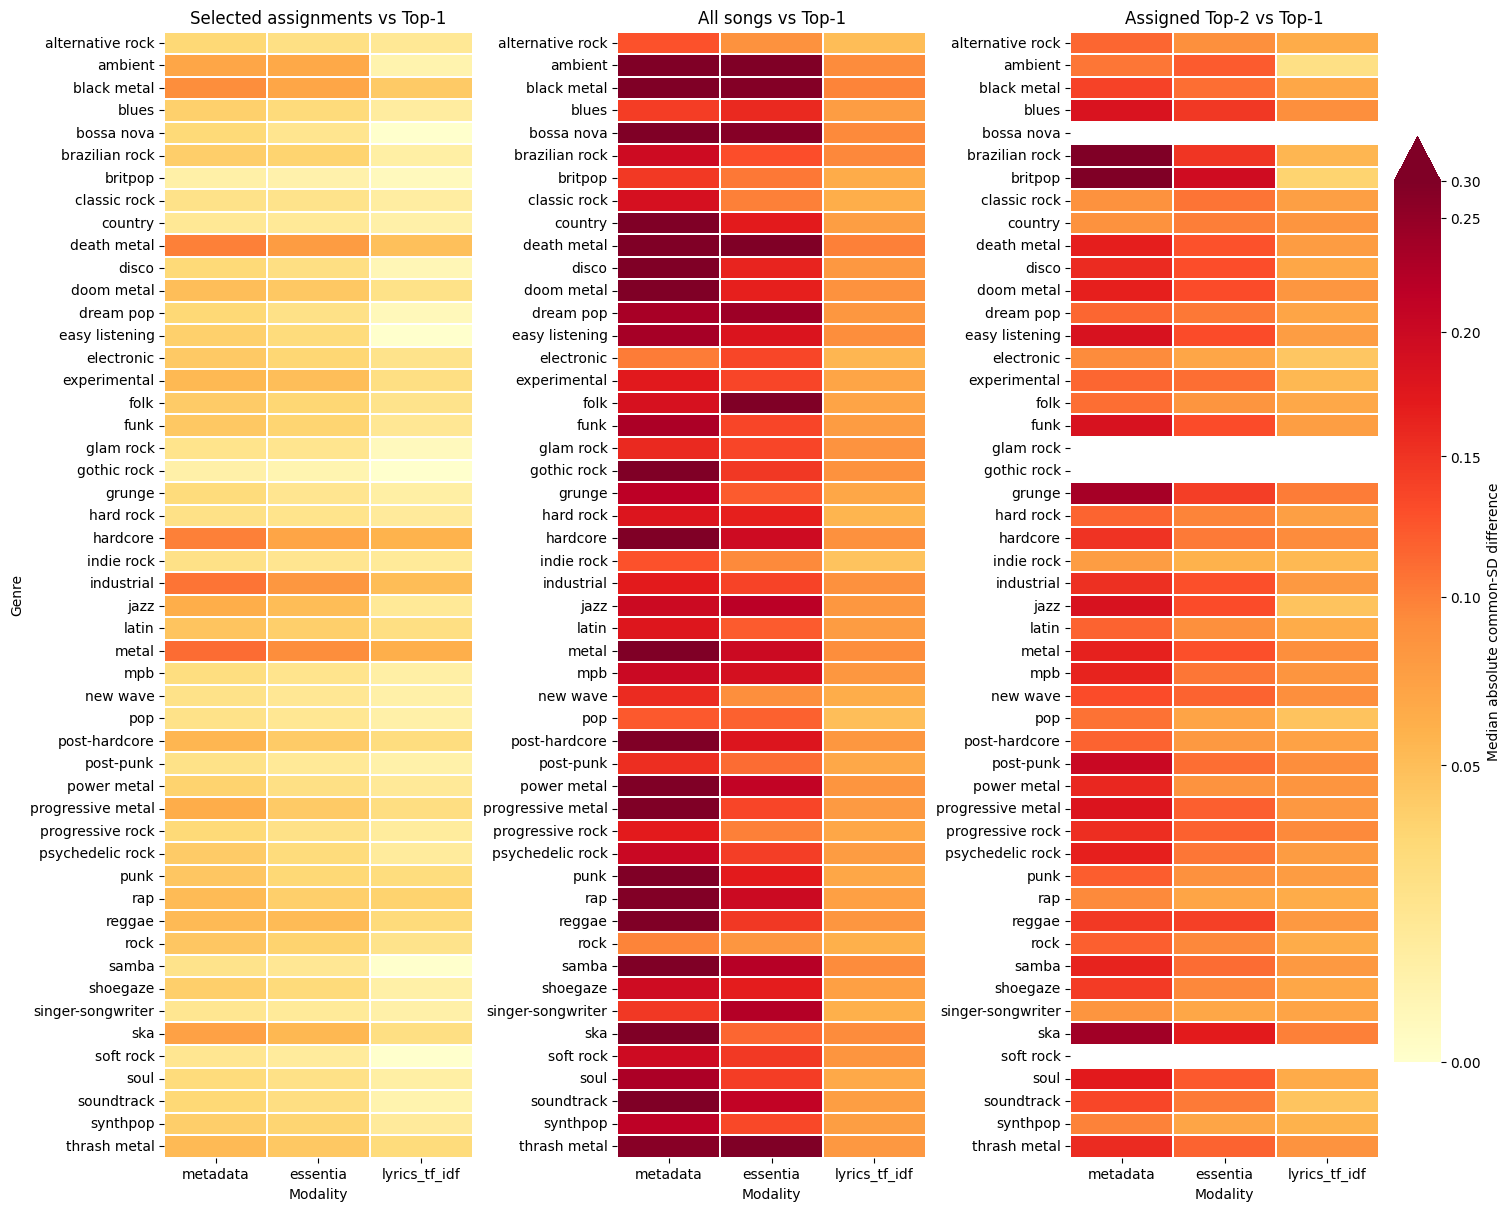

,genre,assigned_songs,reassigned_top2_songs,share_assigned_top2
27,metal,1021,749,0.733595
22,hardcore,1201,870,0.724396
24,industrial,799,553,0.692115
9,death metal,958,632,0.659708
2,black metal,947,582,0.614572
1,ambient,2103,1063,0.505468
15,experimental,1781,861,0.483436
14,electronic,4577,2165,0.473017
37,punk,2073,956,0.461167
31,post-hardcore,1192,548,0.459732


In [25]:
overview_same_reference = matched.groupby("modality", as_index=False).agg(
    selected_vs_top1=("abs_selected_common", "median"),
    all_songs_vs_top1=("abs_all_common", "median"),
    assigned_top2_vs_top1=("abs_assigned_top2_common", "median"),
    compared_cells=("abs_selected_common", "count"),
    top2_compared_cells=("abs_assigned_top2_common", "count"),
)

overall_same_reference = pd.DataFrame({
    "comparison": ["Selected vs Top-1", "All songs vs Top-1", "Assigned Top-2 vs Top-1"],
    "median_absolute_common_sd_difference": [
        matched["abs_selected_common"].median(),
        matched["abs_all_common"].median(),
        matched["abs_assigned_top2_common"].median(),
    ],
    "compared_cells": [
        matched["abs_selected_common"].count(),
        matched["abs_all_common"].count(),
        matched["abs_assigned_top2_common"].count(),
    ],
})

display(overview_same_reference.round(3))
display(overall_same_reference.round(3))

heat_same_reference = matched.groupby(["genre", "modality"], as_index=False).agg(
    selected_vs_top1=("abs_selected_common", "median"),
    all_songs_vs_top1=("abs_all_common", "median"),
    assigned_top2_vs_top1=("abs_assigned_top2_common", "median"),
)

values = heat_same_reference[["selected_vs_top1", "all_songs_vs_top1", "assigned_top2_vs_top1"]].to_numpy(dtype=float)
vmax = np.nanpercentile(values, 95)
if not np.isfinite(vmax) or vmax <= 0:
    vmax = 1.0

fig, axes = plt.subplots(1, 3, figsize=(15, max(8, 0.24 * len(selected_genres))), constrained_layout=True)
for ax, column, title in zip(
    axes,
    ["selected_vs_top1", "all_songs_vs_top1", "assigned_top2_vs_top1"],
    ["Selected assignments vs Top-1", "All songs vs Top-1", "Assigned Top-2 vs Top-1"],
):
    matrix = heat_same_reference.pivot(index="genre", columns="modality", values=column).reindex(
        index=sorted(selected_genres), columns=MODALITIES
    )
    sns.heatmap(
        matrix,
        ax=ax,
        cmap="YlOrRd",
        norm=PowerNorm(gamma=0.65, vmin=0, vmax=vmax, clip=True),
        mask=matrix.isna(),
        linewidths=0.15,
        cbar=ax is axes[2],
        cbar_kws={"label": "Median absolute common-SD difference", "extend": "max"},
    )
    ax.set_title(title)
    ax.set_xlabel("Modality")
    ax.set_ylabel("Genre" if ax is axes[0] else "")

fig.savefig(PLOT_DIR / "selected_vs_all_songs_top1_same_reference_heatmap.png", dpi=250, bbox_inches="tight")
plt.show()

overview_same_reference.to_csv(OUTPUT_DIR / "selected_vs_all_songs_top1_overview.csv", index=False)
overall_same_reference.to_csv(OUTPUT_DIR / "selected_vs_all_songs_top1_overall.csv", index=False)

assigned_top2_summary = (
    assignments.merge(catalog[["id", "top1_genre"]], on="id", how="inner")
    .assign(is_reassigned=lambda x: x["genre"] != x["top1_genre"])
    .groupby("genre", as_index=False)
    .agg(assigned_songs=("id", "nunique"), reassigned_top2_songs=("is_reassigned", "sum"))
)
assigned_top2_summary["share_assigned_top2"] = assigned_top2_summary["reassigned_top2_songs"] / assigned_top2_summary["assigned_songs"]
display(assigned_top2_summary.sort_values("share_assigned_top2", ascending=False).head(15))
assigned_top2_summary.to_csv(OUTPUT_DIR / "assigned_top2_counts_by_genre.csv", index=False)


In [26]:
def bootstrap_smd_matrix(values, selected_mask, baseline_mask, reference_std, reps=500, seed=42, rep_batch=50, feature_batch=64):
    values = np.asarray(values, dtype=np.float32)
    selected_mask = np.asarray(selected_mask, dtype=bool)
    baseline_mask = np.asarray(baseline_mask, dtype=bool)
    reference_std = np.asarray(reference_std, dtype=float)

    n_songs, n_features = values.shape
    estimates = np.full((reps, n_features), np.nan, dtype=np.float32)
    generator = np.random.default_rng(seed)
    probabilities = np.full(n_songs, 1 / n_songs)

    for rep_start in range(0, reps, rep_batch):
        rep_end = min(rep_start + rep_batch, reps)
        weights = generator.multinomial(n_songs, probabilities, size=rep_end - rep_start).astype(np.float32)
        wa = weights[:, selected_mask]
        wb = weights[:, baseline_mask]

        for feature_start in range(0, n_features, feature_batch):
            feature_end = min(feature_start + feature_batch, n_features)
            block = values[:, feature_start:feature_end]
            a = block[selected_mask]
            b = block[baseline_mask]
            a_finite = np.isfinite(a).astype(np.float32)
            b_finite = np.isfinite(b).astype(np.float32)
            a_values = np.where(np.isfinite(a), a, 0)
            b_values = np.where(np.isfinite(b), b, 0)

            a_counts = wa @ a_finite
            b_counts = wb @ b_finite
            a_means = np.divide(wa @ a_values, a_counts, out=np.full_like(a_counts, np.nan), where=a_counts >= 2)
            b_means = np.divide(wb @ b_values, b_counts, out=np.full_like(b_counts, np.nan), where=b_counts >= 2)
            estimates[rep_start:rep_end, feature_start:feature_end] = (
                (a_means - b_means) / reference_std[feature_start:feature_end]
            )

    count = np.isfinite(estimates).sum(axis=0)
    low = np.full(n_features, np.nan)
    high = np.full(n_features, np.nan)
    for j in range(n_features):
        if count[j] >= 0.8 * reps:
            low[j], high[j] = np.percentile(estimates[np.isfinite(estimates[:, j]), j], [2.5, 97.5])
    return low, high, count


candidates = matched[matched["window_start"].isin(BOOTSTRAP_YEARS)].copy()
groups = (
    candidates.groupby(["modality", "window_start", "genre"], as_index=False)
    .agg(selected_n=("selected_n", "max"))
    .sort_values(["modality", "window_start", "selected_n"], ascending=[True, True, False])
    .groupby(["modality", "window_start"], group_keys=False)
    .head(BOOTSTRAP_EXAMPLES_PER_MODALITY_YEAR)
)
examples = candidates.merge(
    groups[["modality", "window_start", "genre"]],
    on=["modality", "window_start", "genre"],
    how="inner",
)

print("Feature/genre/window bootstrap comparisons:", len(examples))
print("Bootstrap draws per comparison:", BOOTSTRAP_REPS)

assigned_ids = assignments.groupby("genre")["id"].agg(set).to_dict()
bootstrap_rows = []

for i, ((modality, year, genre), rows) in enumerate(examples.groupby(["modality", "window_start", "genre"], sort=True)):
    period = song_tables[modality]
    period = period[period["release"].between(year, year + WINDOW_SIZE - 1)].set_index("id")
    selected_ids = period.index.intersection(assigned_ids[genre])
    baseline_ids = period.index[period["top1_genre"].eq(genre)]
    union_ids = selected_ids.union(baseline_ids)
    union = period.loc[union_ids]

    features = rows["feature"].tolist()
    values = union[features].to_numpy(dtype=np.float32)
    selected_mask = union.index.isin(selected_ids)
    baseline_mask = union.index.isin(baseline_ids)
    stds = rows["global_std"].to_numpy(dtype=float)

    low, high, counts = bootstrap_smd_matrix(
        values, selected_mask, baseline_mask, stds,
        reps=BOOTSTRAP_REPS, seed=SEED + i,
        rep_batch=BOOTSTRAP_REP_BATCH, feature_batch=BOOTSTRAP_FEATURE_BATCH,
    )

    result = rows[["modality", "genre", "feature", "window_start", "window_end", "selected_n", "baseline_n"]].copy()
    result["smd"] = rows["smd_selected_common"].to_numpy()
    result["global_std"] = stds
    result["ci_lower"] = low
    result["ci_upper"] = high
    result["valid_replicates"] = counts
    result["scale"] = "global_window_sd_fixed"
    bootstrap_rows.append(result)
    print("Bootstrapped:", modality, year, genre, len(features), "features")

bootstrap_results = pd.concat(bootstrap_rows, ignore_index=True) if bootstrap_rows else pd.DataFrame(
    columns=["modality", "genre", "feature", "window_start", "window_end", "selected_n", "baseline_n", "smd", "global_std", "ci_lower", "ci_upper", "valid_replicates", "scale"]
)
display(bootstrap_results.head(20))
print("Bootstrap intervals available:", bootstrap_results["ci_lower"].notna().sum())


Feature/genre/window bootstrap comparisons: 11078
Bootstrap draws per comparison: 500
Bootstrapped: essentia 1980 new wave 836 features
Bootstrapped: essentia 1980 post-punk 836 features
Bootstrapped: essentia 2000 indie rock 841 features
Bootstrapped: essentia 2000 pop 841 features
Bootstrapped: essentia 2015 pop 842 features
Bootstrapped: essentia 2015 rap 842 features
Bootstrapped: lyrics_tf_idf 1980 new wave 996 features
Bootstrapped: lyrics_tf_idf 1980 post-punk 996 features
Bootstrapped: lyrics_tf_idf 2000 indie rock 1000 features
Bootstrapped: lyrics_tf_idf 2000 pop 1000 features
Bootstrapped: lyrics_tf_idf 2015 pop 1000 features
Bootstrapped: lyrics_tf_idf 2015 rap 1000 features
Bootstrapped: metadata 1980 new wave 8 features
Bootstrapped: metadata 1980 post-punk 8 features
Bootstrapped: metadata 2000 indie rock 8 features
Bootstrapped: metadata 2000 pop 8 features
Bootstrapped: metadata 2015 pop 8 features
Bootstrapped: metadata 2015 rap 8 features


,modality,genre,feature,window_start,window_end,selected_n,baseline_n,smd,global_std,ci_lower,ci_upper,valid_replicates,scale
0,essentia,new wave,lowlevel.average_loudness,1980,1984,420,370.0,0.016495,0.106928,0.007061,0.026307,500,global_window_sd_fixed
1,essentia,new wave,lowlevel.barkbands.mean_0,1980,1984,420,370.0,0.004269,0.000983,-0.042500,0.055100,500,global_window_sd_fixed
2,essentia,new wave,lowlevel.barkbands.mean_1,1980,1984,420,370.0,0.015851,0.006423,-0.050224,0.077651,500,global_window_sd_fixed
3,essentia,new wave,lowlevel.barkbands.mean_2,1980,1984,420,370.0,0.009193,0.002685,-0.031231,0.057311,500,global_window_sd_fixed
4,essentia,new wave,lowlevel.barkbands.mean_3,1980,1984,420,370.0,0.016148,0.001892,-0.018281,0.053096,500,global_window_sd_fixed
5,essentia,new wave,lowlevel.barkbands.mean_4,1980,1984,420,370.0,0.012249,0.002105,-0.024096,0.054410,500,global_window_sd_fixed
6,essentia,new wave,lowlevel.barkbands.mean_5,1980,1984,420,370.0,0.006335,0.001327,-0.027511,0.047379,500,global_window_sd_fixed
7,essentia,new wave,lowlevel.barkbands.mean_6,1980,1984,420,370.0,0.009093,0.000968,-0.025515,0.043388,500,global_window_sd_fixed
8,essentia,new wave,lowlevel.barkbands.mean_7,1980,1984,420,370.0,-0.017020,0.000854,-0.059966,0.029154,500,global_window_sd_fixed
9,essentia,new wave,lowlevel.barkbands.mean_8,1980,1984,420,370.0,-0.008083,0.000949,-0.039141,0.030981,500,global_window_sd_fixed


Bootstrap intervals available: 11078


In [27]:
feature_overview = []

for modality in MODALITIES:
    all_features = set(feature_sets[modality])
    smd_features = set(comparisons.loc[
        (comparisons["modality"] == modality) & comparisons["smd_selected_common"].notna(), "feature"
    ])
    top2_features = set(comparisons.loc[
        (comparisons["modality"] == modality) & comparisons["smd_assigned_top2_common"].notna(), "feature"
    ])
    bootstrap_features = set(bootstrap_results.loc[
        (bootstrap_results["modality"] == modality)
        & bootstrap_results["ci_lower"].notna()
        & bootstrap_results["ci_upper"].notna(), "feature"
    ])
    feature_overview.append({
        "modality": modality,
        "total_numeric_features": len(all_features),
        "features_with_valid_smd": len(smd_features),
        "features_with_valid_top2_smd": len(top2_features),
        "features_with_bootstrap_ci": len(bootstrap_features),
    })

feature_overview = pd.DataFrame(feature_overview)
display(feature_overview)

outliers = matched.loc[
    matched["smd_selected_common"].abs() > 5,
    ["modality", "genre", "feature", "window_start", "selected_n", "baseline_n", "global_std", "smd_selected_common"],
].copy()
print("Common-standardized differences above 5:", len(outliers))
display(outliers.sort_values("smd_selected_common", key=lambda x: x.abs(), ascending=False).head(20))


,modality,total_numeric_features,features_with_valid_smd,features_with_valid_top2_smd,features_with_bootstrap_ci
0,metadata,8,8,8,8
1,essentia,1034,845,845,842
2,lyrics_tf_idf,1000,1000,1000,1000


Common-standardized differences above 5: 0


,modality,genre,feature,window_start,selected_n,baseline_n,global_std,smd_selected_common


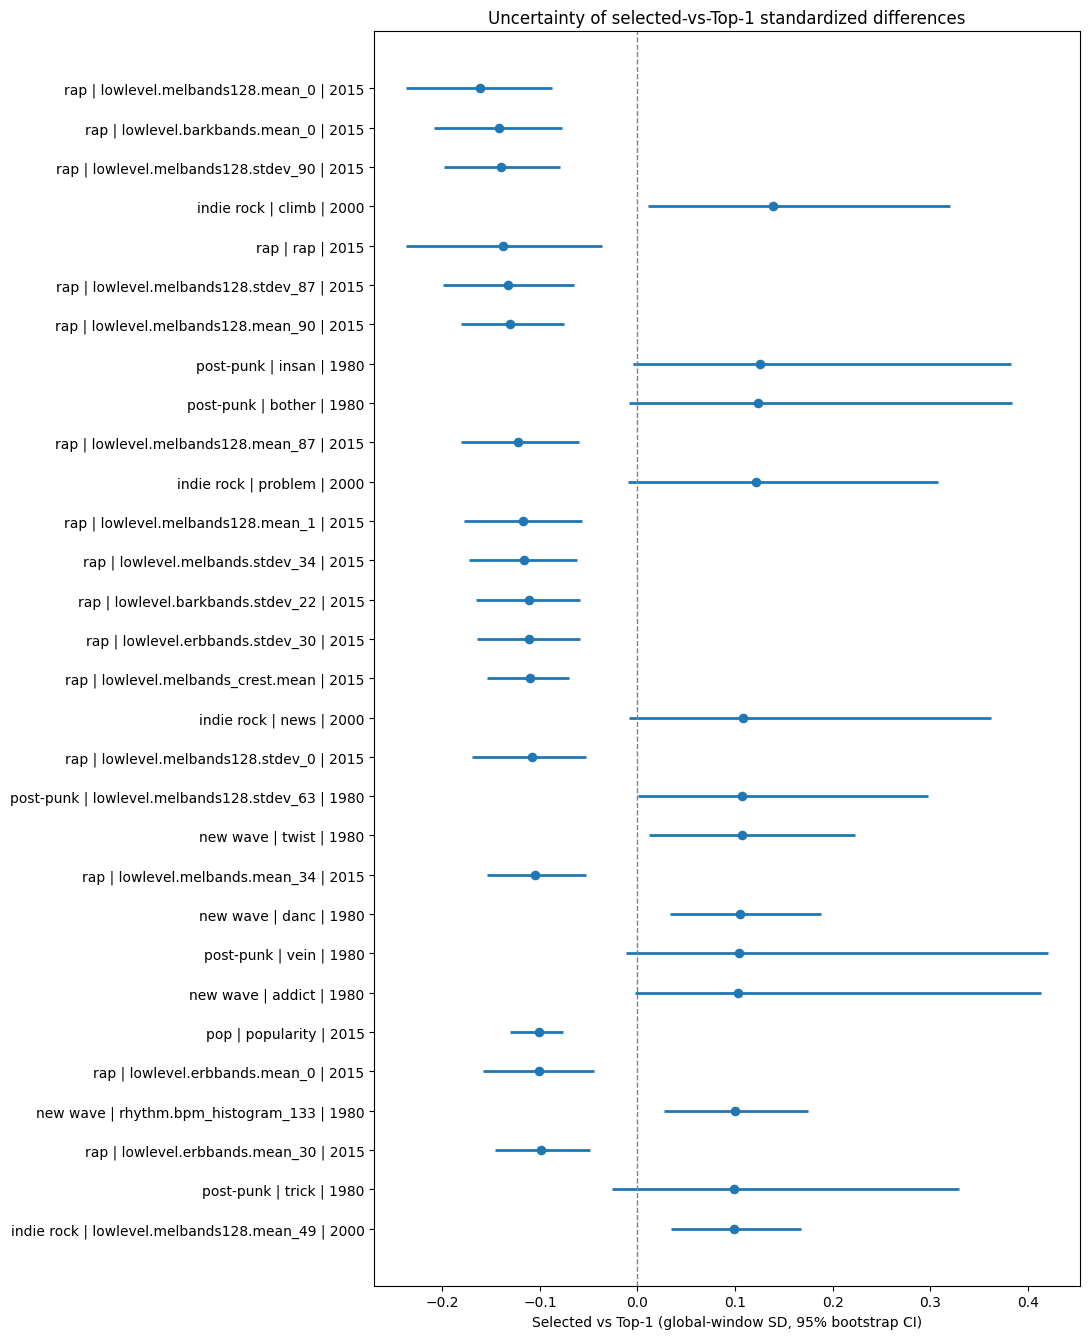

Saved results to: plots


In [28]:
if not bootstrap_results.empty:
    plot = (
        bootstrap_results.dropna(subset=["ci_lower", "ci_upper"])
        .sort_values("smd", key=lambda x: x.abs(), ascending=False)
        .head(BOOTSTRAP_PLOT_LIMIT)
        .reset_index(drop=True)
    )
    if not plot.empty:
        plot["label"] = plot["genre"].astype(str) + " | " + plot["feature"].astype(str) + " | " + plot["window_start"].astype(str)
        fig, ax = plt.subplots(figsize=(11, max(5, 0.45 * len(plot))))
        y = np.arange(len(plot))
        ax.hlines(y, plot["ci_lower"], plot["ci_upper"], linewidth=2)
        ax.scatter(plot["smd"], y, s=35, zorder=3)
        ax.axvline(0, color="gray", linestyle="--", linewidth=1)
        ax.set_yticks(y, plot["label"])
        ax.invert_yaxis()
        ax.set_xlabel("Selected vs Top-1 (global-window SD, 95% bootstrap CI)")
        ax.set_title("Uncertainty of selected-vs-Top-1 standardized differences")
        plt.tight_layout()
        fig.savefig(PLOT_DIR / "top1_smd_bootstrap_intervals.png", dpi=250, bbox_inches="tight")
        plt.show()

comparisons.to_parquet(OUTPUT_DIR / "feature_genre_window_smd.parquet", index=False)
feature_scores.to_csv(OUTPUT_DIR / "feature_smd_summary.csv", index=False)
modality_scores.to_csv(OUTPUT_DIR / "modality_smd_summary.csv", index=False)
summary.to_csv(OUTPUT_DIR / "dataset_summary.csv", index=False)
bootstrap_results.to_csv(OUTPUT_DIR / "smd_bootstrap_examples.csv", index=False)
feature_overview.to_csv(OUTPUT_DIR / "feature_coverage_overview.csv", index=False)
print("Saved results to:", OUTPUT_DIR)
